# From the raw profiles to the GTT classification

This walkthrough follows the glucose tolerance test (GTT) analysis of the paper from the raw QIRT-ELISA profiles
of 9 rats (LZ, OZ and ZDF, 3 each) to the classification results and figures. Every step runs one of the scripts
in this folder and shows its result next to the files the paper used (`data/`).

The calibration, the feature extraction and the figures take seconds and are run in full. The nested
cross-validation of the 81 combinations for all 20 label assignments (about 1.5 h) is shown from its saved
results, and one selector is rerun to show that it reproduces. The whole notebook runs in about 2 minutes.

Run it from this folder with Jupyter and the packages in `../requirements.txt`. Everything it writes goes to `outputs/`.

In [1]:
import filecmp
import io
import shutil
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage

PILImage.MAX_IMAGE_PIXELS = None  # the 600-dpi figures are larger than PIL's default limit

ROOT = Path.cwd()                 # this folder (gtt)
DATA = ROOT / "data"
OUT = ROOT / "outputs"
LABELS = {"healthy": "LZ", "pre-diabetic": "OZ", "diabetic": "ZDF"}


def run(script, *args, last=None):
    """Run a script of this folder with this notebook's Python; print its output (or its last lines)."""
    result = subprocess.run([sys.executable, script, *args], cwd=ROOT, capture_output=True, text=True)
    if result.returncode:
        print(result.stdout, result.stderr)
        raise RuntimeError(f"{script} failed")
    lines = result.stdout.replace(f"{ROOT}/", "").strip().splitlines()   # paths relative to this folder
    print("\n".join(lines[-last:] if last else lines))


def show(*stems, width=1000, gap=24):
    """Display one figure of outputs/figures/, or several side by side at the same height, at the given total width
    and in 256 colours so that the notebook stays small."""
    images = [PILImage.open(OUT / "figures" / f"{stem}.png").convert("RGB") for stem in stems]
    height = round((width - gap * (len(images) - 1)) / sum(image.width / image.height for image in images))
    widths = [round(image.width * height / image.height) for image in images[:-1]]
    widths.append(width - gap * (len(images) - 1) - sum(widths))      # the last figure fills the row exactly
    row = PILImage.new("RGB", (width, height), "white")
    x = 0
    for image, w in zip(images, widths):
        row.paste(image.resize((w, height), PILImage.LANCZOS), (x, 0))
        x += w + gap
    row = row.quantize(colors=256, method=PILImage.Quantize.MEDIANCUT, dither=PILImage.Dither.NONE)
    buffer = io.BytesIO()
    row.save(buffer, format="PNG", optimize=True)
    display(Image(buffer.getvalue()))

## 1. Raw data

`data/raw/gtt_post_injection.csv` holds, for each rat, the 24 samples of the normalized QIRT-ELISA signal (F/Fmax)
of insulin, C-peptide and glucagon from the glucose injection (t = 0) to 61.3 min, with the glucometer glucose (mM)
and the ELISA values (pM) at the blood-sampling times (0, 16, 29.3, 45.3 and 61.3 min).
`data/raw/gtt_pre_injection.csv` holds the 4 samples before the injection (−10 to −2.5 min).

In [2]:
post = pd.read_csv(DATA / "raw" / "gtt_post_injection.csv")
pre = pd.read_csv(DATA / "raw" / "gtt_pre_injection.csv")
counts = pd.DataFrame({"pre-injection": pre.groupby("animal_id").size(),
                       "post-injection": post.groupby("animal_id").size(),
                       "blood samples": post.dropna(subset=["glucose_mM"]).groupby("animal_id").size()})
counts.insert(0, "phenotype", post.groupby("animal_id").rat_type.first().map(LABELS))
counts.T

animal_id,Rat1,Rat2,Rat3,Rat4,Rat5,Rat6,Rat7,Rat8,Rat9
phenotype,LZ,LZ,LZ,OZ,OZ,OZ,ZDF,ZDF,ZDF
pre-injection,4,4,4,4,4,4,4,4,4
post-injection,24,24,24,24,24,24,24,24,24
blood samples,4,5,5,5,5,5,5,5,5


In [3]:
post[post.animal_id == "Rat2"].dropna(subset=["glucose_mM"]).set_index("timepoint")[
    ["glucose_mM", "insulin_ELISA_pM", "c_peptide_ELISA_pM", "glucagon_ELISA_pM"]].round(1).T

timepoint,0.000000,16.000000,29.333333,45.333333,61.333333
glucose_mM,5.9,12.3,13.5,12.5,9.2
insulin_ELISA_pM,27.7,332.9,256.2,260.0,227.7
c_peptide_ELISA_pM,110.0,1356.4,1235.8,1190.2,1168.1
glucagon_ELISA_pM,6.5,1.2,0.7,0.7,0.7


## 2. Calibration

`src/calibrate.py` smooths each rat's post-injection signal with a Hamming-weighted moving average
(5 samples) and fits a straight line of the rat's ELISA values on the smoothed signal at the blood-sampling times,
C = slope · x + intercept. The line converts the profile to pM; concentrations below 0 are set to 0.

In [4]:
run("src/calibrate.py", last=3)
for name in ("concentration_timeseries.csv", "calibration_parameters.csv"):
    same = filecmp.cmp(OUT / "calibration" / name, DATA / "concentrations" / name, shallow=False)
    print(f"{name}: {'identical to' if same else 'DIFFERENT from'} data/concentrations/")

9 rats, 252 samples; 3 of 27 lines fitted to 4 ELISA values (Rat1), the rest to 5
  Saved: outputs/calibration/concentration_timeseries.csv
  Saved: outputs/calibration/calibration_parameters.csv
concentration_timeseries.csv: identical to data/concentrations/
calibration_parameters.csv: identical to data/concentrations/


In [5]:
parameters = pd.read_csv(OUT / "calibration" / "calibration_parameters.csv")
parameters.assign(phenotype=parameters.rat_type.map(LABELS)).pivot(
    index=["animal_id", "phenotype"], columns="hormone", values="slope_pM").round(0).T

animal_id,Rat1,Rat2,Rat3,Rat4,Rat5,Rat6,Rat7,Rat8,Rat9
phenotype,LZ,LZ,LZ,OZ,OZ,OZ,ZDF,ZDF,ZDF
hormone,,,,,,,,,
c_peptide,3660.0,4668.0,4231.0,12196.0,7931.0,6692.0,529.0,965.0,12903.0
glucagon,14.0,16.0,2.0,3.0,80.0,37.0,2.0,9.0,4.0
insulin,1125.0,914.0,1306.0,716.0,5635.0,5191.0,162.0,45.0,2719.0


The agreement with ELISA is checked by leaving out each ELISA value of the LZ and ZDF rats in turn and predicting
it from the line refitted to the rat's other values (`src/held_out_elisa.py`; main-text Fig. 5 d–e):

In [6]:
run("src/held_out_elisa.py")
for name in ("held_out_elisa.csv", "held_out_elisa_summary.csv"):
    same = filecmp.cmp(OUT / "calibration" / name, DATA / "concentrations" / name, shallow=False)
    print(f"{name}: {'identical to' if same else 'DIFFERENT from'} data/concentrations/")

hormone  n   ccc  mae_pM  bias_pM  loa_low_pM  loa_high_pM  negative_predictions_set_to_0
  insulin 29 0.918  81.652   18.879    -197.530      235.289                              0
c_peptide 29 0.911 394.865  153.931   -1079.691     1387.552                              0
 glucagon 29 0.211   1.547   -0.148      -4.941        4.646                              1
held_out_elisa.csv: identical to data/concentrations/
held_out_elisa_summary.csv: identical to data/concentrations/


## 3. Feature extraction

`src/extract_features.py` computes 192 features per rat from the calibrated profiles (the GTT
feature table of the SI) and keeps 181 of them as the classification matrix.

In [7]:
run("src/extract_features.py", last=6)


Comparison with data/features/:
  gtt_features_all.csv: identical
  gtt_X.csv: identical
  gtt_y.csv: identical
  gtt_meta.csv: identical


In [8]:
X = pd.read_csv(DATA / "features" / "gtt_X.csv")
meta = pd.read_csv(DATA / "features" / "gtt_meta.csv")
print(f"classification matrix: {X.shape[0]} rats x {X.shape[1]} features, {int(X.isna().sum().sum())} missing values")
X.assign(rat=meta.animal_id, phenotype=meta.rat_type.map(LABELS)).set_index(["rat", "phenotype"])[
    ["c_peptide_pulsatility_index", "c_peptide_response_cv_pct", "insulin_trend_r_squared",
     "insulin_glucose_corr_r"]].round(3)

classification matrix: 9 rats x 181 features, 11 missing values


,,c_peptide_pulsatility_index,c_peptide_response_cv_pct,insulin_trend_r_squared,insulin_glucose_corr_r
rat,phenotype,,,,
Rat1,LZ,0.830,38.745,0.037,0.860
Rat2,LZ,0.834,48.807,0.193,0.703
Rat3,LZ,0.739,45.452,0.092,0.824
Rat4,OZ,0.126,20.174,0.593,0.313
Rat5,OZ,0.153,16.949,0.486,-0.867
Rat6,OZ,0.201,11.933,0.738,-0.573
Rat7,ZDF,0.064,5.486,0.224,-0.788
Rat8,ZDF,0.056,2.935,0.644,-0.411
Rat9,ZDF,0.259,23.262,0.792,0.289


## 4. Nested cross-validation of 81 combinations

`src/run_classification.py` evaluates every combination of 9 feature selectors and 9 classifiers by
nested leave-one-rat-out cross-validation of the six LZ and ZDF rats. The three OZ rats are in every training set
with the diabetic label and are never held out. In each fold the selector, the number of features (3, 5 or 10,
chosen in the inner loop) and the classifier are fitted on the other rats. The same is repeated for all 20 ways
of labelling three of the six rats as diabetic, which gives an exact label test. `src/summarize.py`
summarizes the saved results of the paper's run:

In [9]:
run("src/summarize.py", last=4)

True labels: 28 of 81 combinations classify all six rats correctly; mean macro-F1 0.823
  Most selected features (168 held-out fits of the perfect combinations): c_peptide_pulsatility_index 147, c_peptide_response_cv_pct 68, c_peptide_peak_fold_change 55, c_peptide_first_phase_dominance 47
Exact label test: 4 of 20 assignments reach the best macro-F1 of the true labels (assignments 2, 16, 17, 19); p = 0.20
  Saved in outputs/classification/reported


In [10]:
scores = pd.read_csv(DATA / "classification" / "scores_by_assignment.csv")
true = scores[scores.true_labels]
true.pivot(index="selector", columns="classifier", values="macro_f1").round(2)

classifier,DecisionTree,KNN,LDA,LogReg_L1,LogReg_L2,NaiveBayes,RandomForest,SVM_linear,SVM_rbf
selector,,,,,,,,,
anova,0.67,0.83,1.00,1.00,0.83,0.62,1.00,1.00,0.83
elastic_net,1.00,0.83,1.00,1.00,0.83,0.33,1.00,1.00,0.83
kruskal,0.62,0.67,0.83,0.49,0.83,0.62,0.83,0.83,0.49
lasso,0.49,0.83,1.00,1.00,0.83,0.62,0.83,1.00,0.67
mrmr,0.62,0.83,0.62,0.83,0.83,0.25,0.83,0.83,0.83
mutual_info,1.00,0.83,0.83,0.83,0.83,0.67,0.83,0.62,0.83
relieff,1.00,1.00,1.00,1.00,1.00,0.62,0.83,1.00,1.00
rf_importance,1.00,0.83,1.00,0.83,1.00,0.62,0.83,1.00,0.62
rfe,1.00,0.83,1.00,1.00,0.83,0.49,0.83,1.00,0.67


The best macro-F1 of the 81 combinations under each of the 20 label assignments (the true labels: Rat7–Rat9
diabetic). Four assignments, the true one included, reach 1.0, so p = 4/20 = 0.20:

In [11]:
maxima = pd.read_csv(OUT / "classification" / "reported" / "assignment_maxima.csv")
maxima.set_index("assignment")[["diabetic_rats", "max_macro_f1", "perfect_combinations"]].round(3)

,diabetic_rats,max_macro_f1,perfect_combinations
assignment,,,
0,Rat1 Rat2 Rat3,0.829,0
1,Rat1 Rat2 Rat7,0.829,0
2,Rat1 Rat2 Rat8,1.000,1
3,Rat1 Rat2 Rat9,0.667,0
4,Rat1 Rat3 Rat7,0.625,0
5,Rat1 Rat3 Rat8,0.829,0
6,Rat1 Rat3 Rat9,0.829,0
7,Rat1 Rat7 Rat8,0.829,0
8,Rat1 Rat7 Rat9,0.486,0


Rerunning one selector (ANOVA, with its nine classifiers) on the true labels, about 20 s, gives the same held-out
predictions, numbers of features and selected features as the saved run, in all 54 fits (9 classifiers x 6 held-out rats):

In [12]:
check = OUT / "notebook" / "classification"
shutil.rmtree(check, ignore_errors=True)
run("src/run_classification.py", "--selector", "anova", "--output-dir", str(check))
key = ["selector", "classifier", "animal_id"]
saved = pd.read_csv(DATA / "classification" / "predictions_by_assignment.csv").query("assignment == 19")
tables = {"predictions": (pd.read_csv(check / "predictions_by_assignment.csv"), saved),
          "features": (pd.read_csv(check / "selected_features_true_labels.csv"),
                       pd.read_csv(DATA / "classification" / "selected_features_true_labels.csv"))}
for name, (new, reference) in tables.items():
    reference = reference[reference.selector == "anova"]
    assert len(new) == len(reference) == 54 and not new.duplicated(key).any() and not reference.duplicated(key).any()
    tables[name] = new.merge(reference, on=key, suffixes=("", "_saved"), validate="one_to_one")
fits, features = tables["predictions"], tables["features"]
assert len(fits) == len(features) == 54
for what, same in (("predictions", fits.prediction.eq(fits.prediction_saved).all()),
                   ("numbers of features", fits.selected_k.eq(fits.selected_k_saved).all()),
                   ("selected features", features.selected_features.eq(features.selected_features_saved).all())):
    print(f"{what}: {'identical' if same else 'DIFFERENT'} in all {len(fits)} held-out fits")

1 jobs (1 label assignments x 1 selectors), 4 workers
  1/1 assignment 19 anova         done (16 s)
  Saved: outputs/notebook/classification/scores_by_assignment.csv
  Saved: outputs/notebook/classification/predictions_by_assignment.csv
  Saved: outputs/notebook/classification/selected_features_true_labels.csv

True labels: 4 of 9 combinations classify all six rats correctly; mean macro-F1 0.864
  Most selected features (24 held-out fits of the perfect combinations): c_peptide_pulsatility_index 24, c_peptide_first_phase_dominance 17, c_peptide_peak_fold_change 12, c_peptide_response_cv_pct 5
Exact label test: needs all 20 label assignments
  Saved in outputs/notebook/classification
predictions: identical in all 54 held-out fits
numbers of features: identical in all 54 held-out fits
selected features: identical in all 54 held-out fits


## 5. Figures

`figures/fig5.py` and `figures/fig6.py` draw main-text Figs. 5 b–e and 6 a–h, and `figures/si.py` the SI figures, from the files in `data/`. All figures are written to `outputs/figures/`.

In [13]:
for script in ("fig5", "fig6", "si"):
    run(f"figures/{script}.py", last=1)

  Saved: outputs/figures/fig5_d_e.png


  Saved: outputs/figures/fig6_h.png


  Saved: outputs/figures/si_sampling_maxima.png


**Fig. 5 b–c:** glucose and the calibrated hormone profiles of the LZ and ZDF rats (mean ± SD).

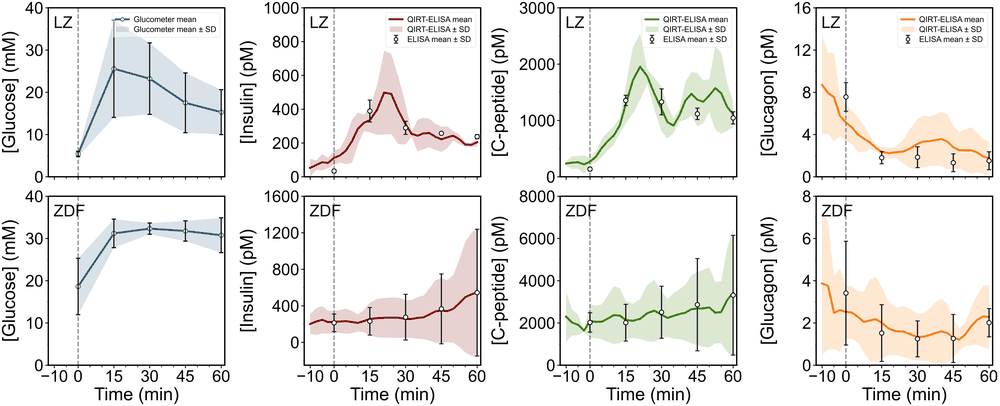

In [14]:
show("fig5_b_c")

**Fig. 5 d–e:** held-out device concentration against ELISA, and Bland–Altman plots.

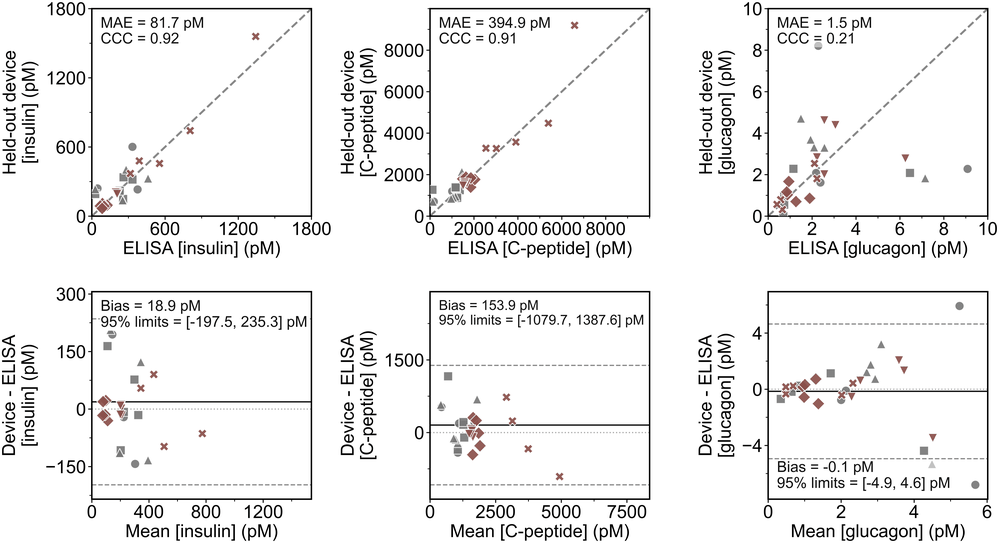

In [15]:
show("fig5_d_e")

**Fig. 6 a:** fasting HOMA-IR, HOMA-β and QUICKI.

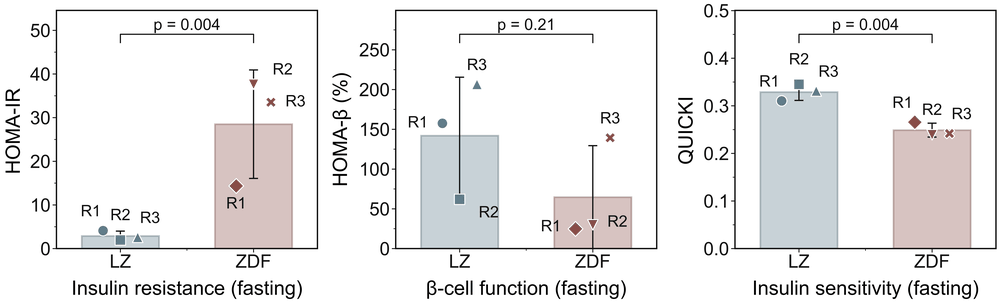

In [16]:
show("fig6_a")

**Fig. 6 b:** insulin–glucagon trajectory of each rat after the glucose injection.

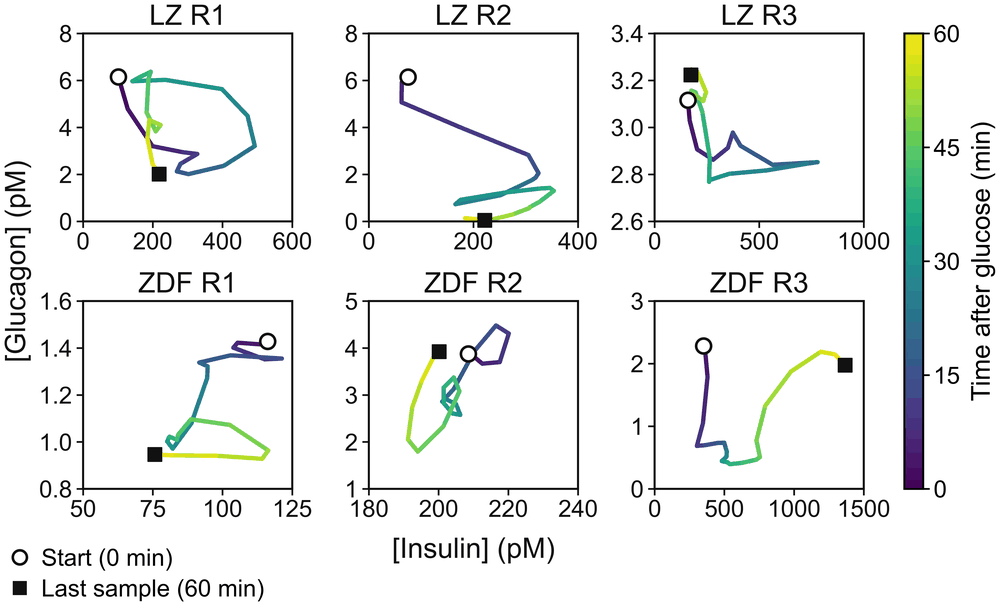

In [17]:
show("fig6_b")

**Fig. 6 c–d:** insulin–glucagon correlation; adapted Matsuda index.

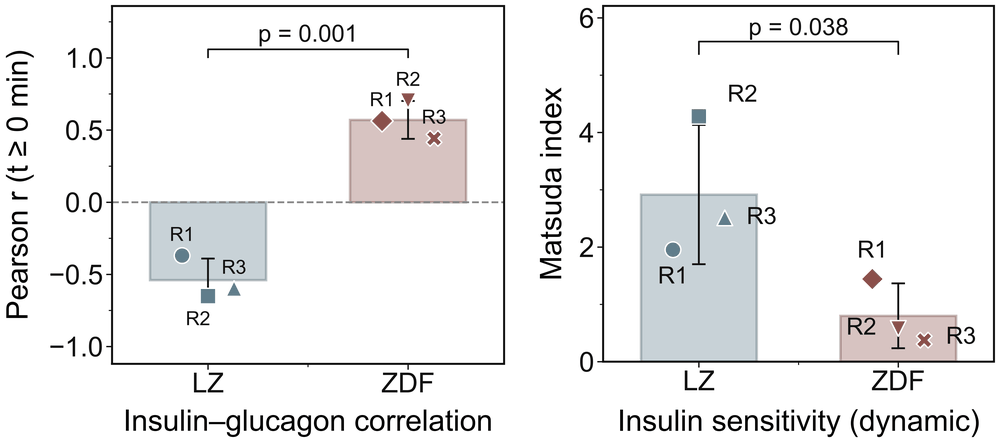

In [18]:
show("fig6_c", "fig6_d")

**Fig. 6 e–f:** features selected by the 28 perfect combinations, and their z-scores.

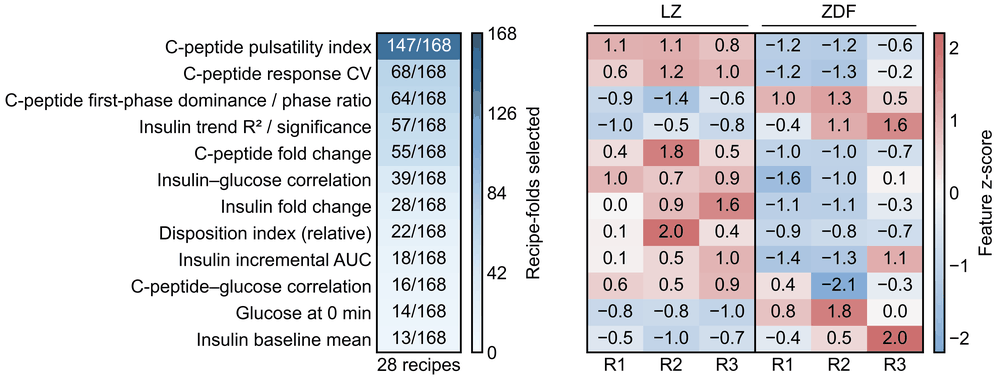

In [19]:
show("fig6_e_f")

**Fig. 6 g–h:** principal component analysis of the 181 features of the six rats, computed without labels; hormone family and feature type of the selected features in the GTT and the fed state. In g, the dashed line and the shaded regions are a shrinkage LDA fitted to the two components of these six rats with their labels: an in-sample illustration, not the boundary of the cross-validated classifiers.

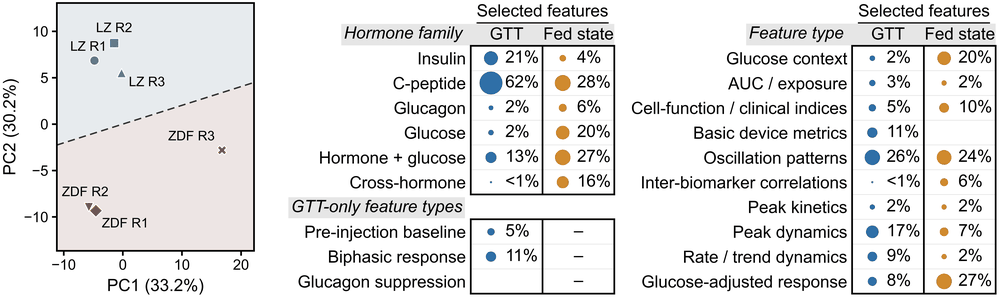

In [20]:
show("fig6_g", "fig6_h")

## 6. Supplementary figures

Glucose and the calibrated profiles of each rat, with the ELISA values.

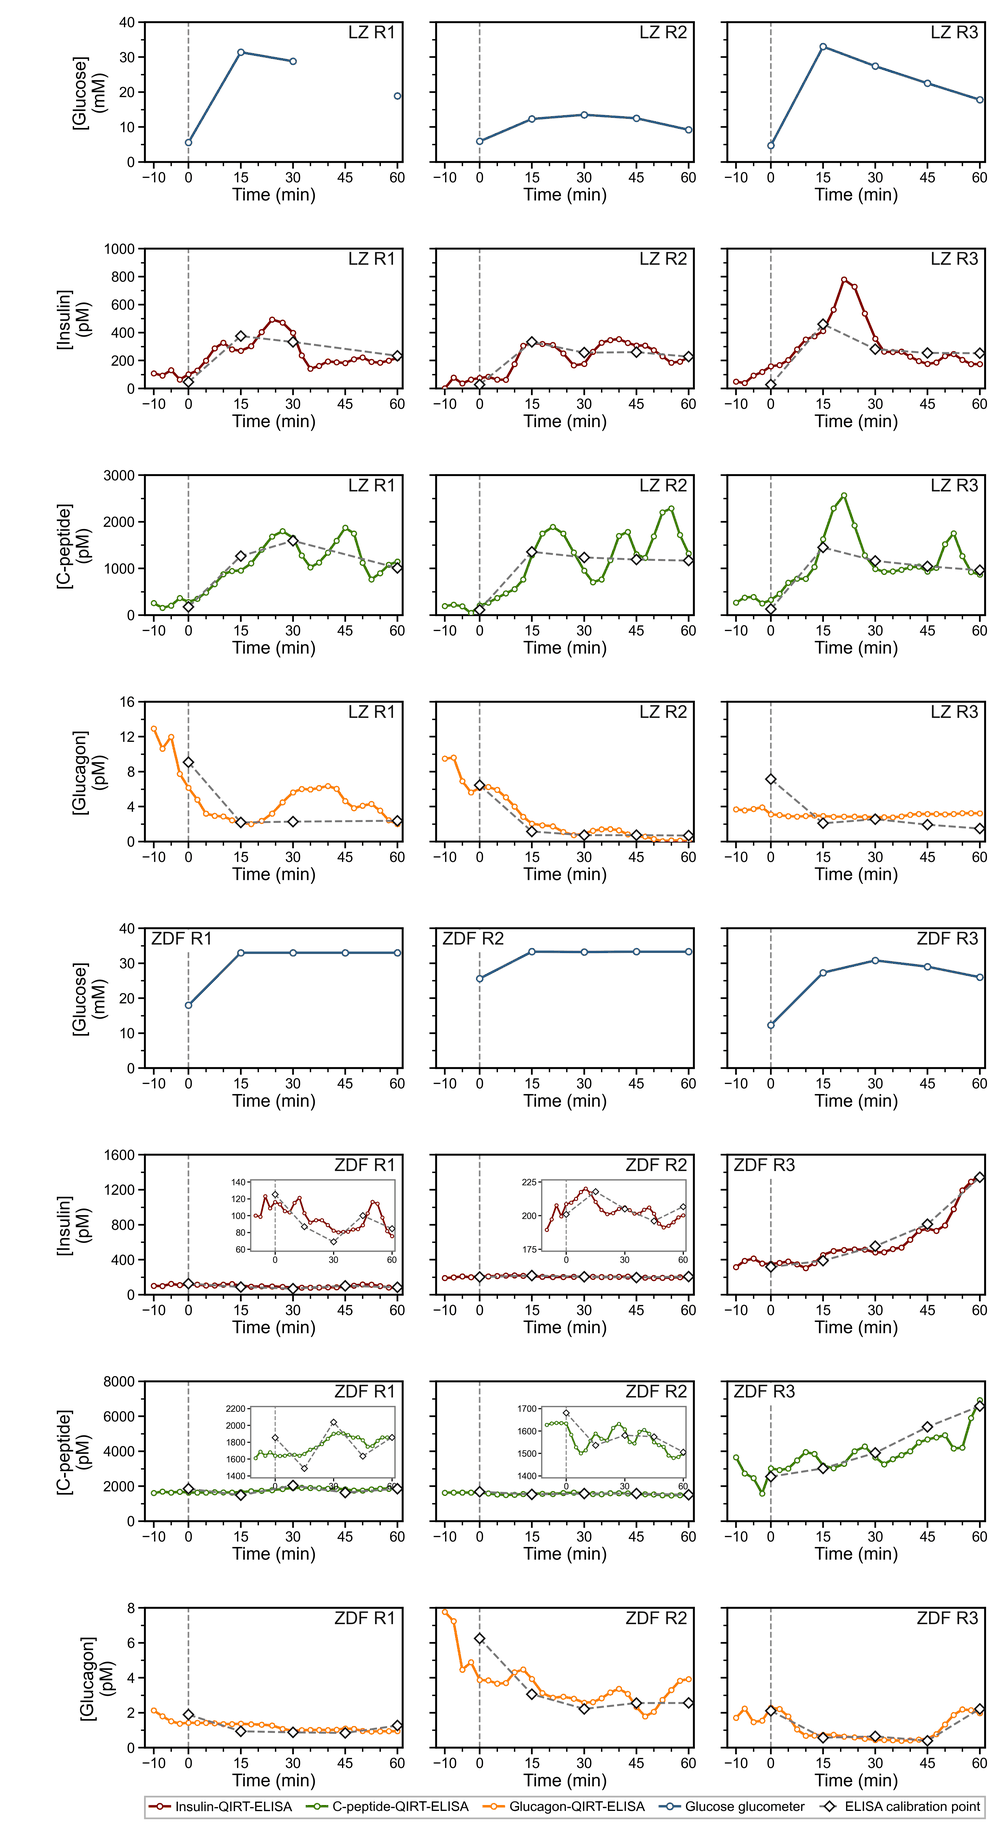

In [21]:
show("si_individual_profiles")

Fasting insulin, C-peptide and glucagon.

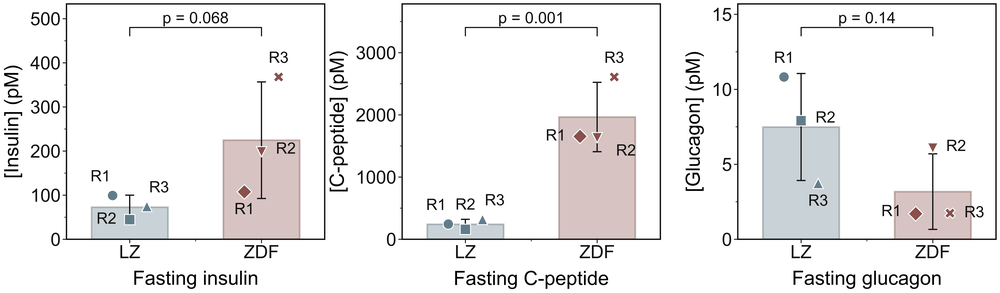

In [22]:
show("si_fasting_levels")

C-peptide–glucagon trajectory of each rat, and the correlation of the two profiles.

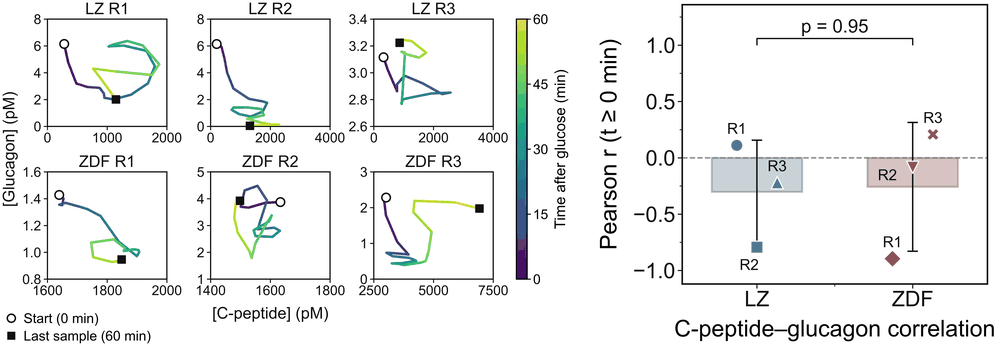

In [23]:
show("si_cpeptide_glucagon_trajectories", "si_cpeptide_glucagon_r")

Insulin–C-peptide trajectory of each rat, and the correlation of the two profiles.

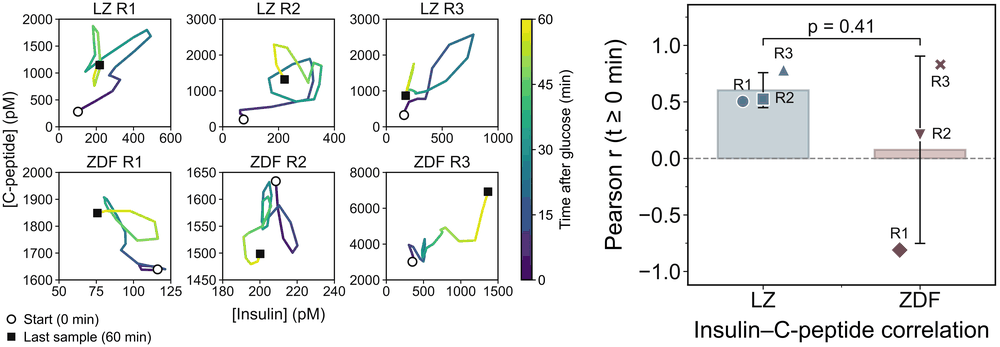

In [24]:
show("si_insulin_cpeptide_trajectories", "si_insulin_cpeptide_r")

Macro-F1 of the 81 combinations with the true labels.

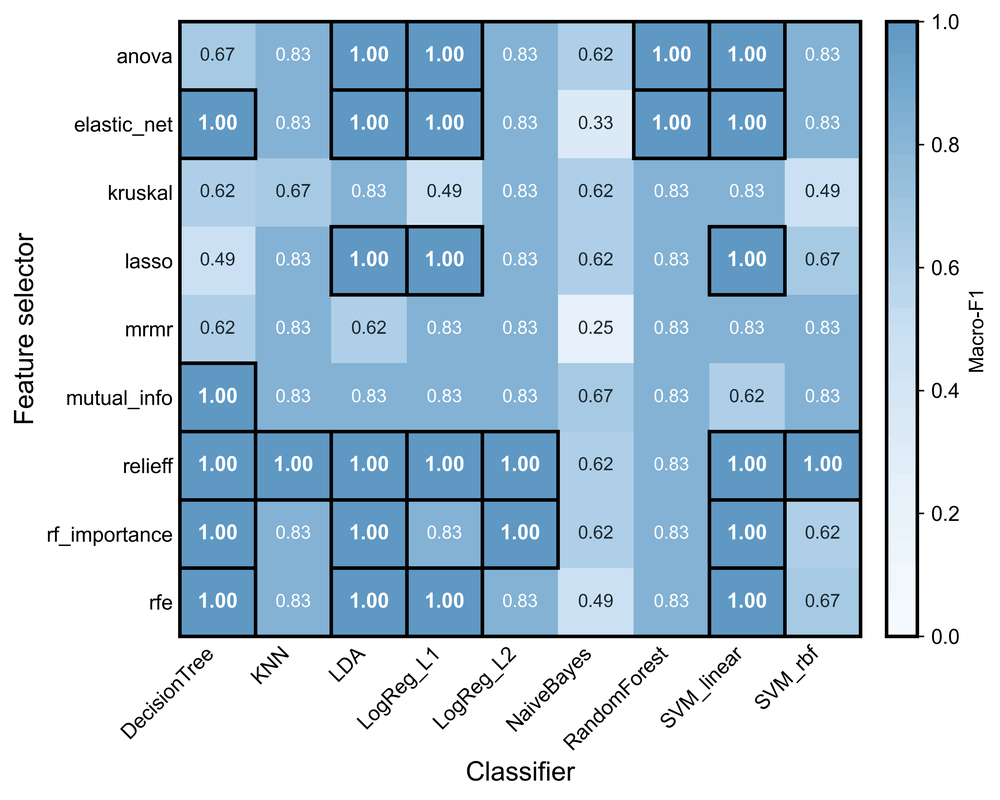

In [25]:
show("si_macro_f1_heatmap")

Exact label test: the cumulative distribution and the histogram of the best macro-F1 under the other 19 label assignments.

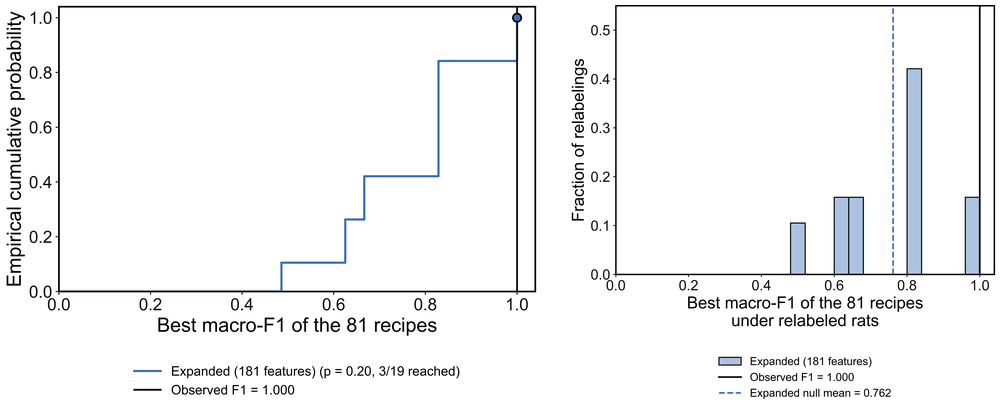

In [26]:
show("si_label_test_ecdf", "si_label_test_null")

Features selected by the 28 perfect combinations, by held-out rat.

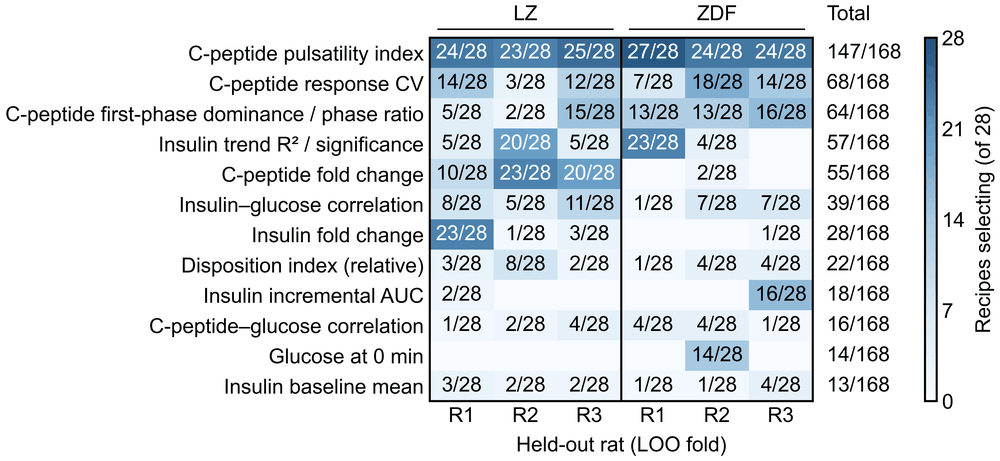

In [27]:
show("si_feature_recurrence_by_rat")

Glucagon relative to the pre-injection level; cumulative C-peptide/insulin exposure ratio.

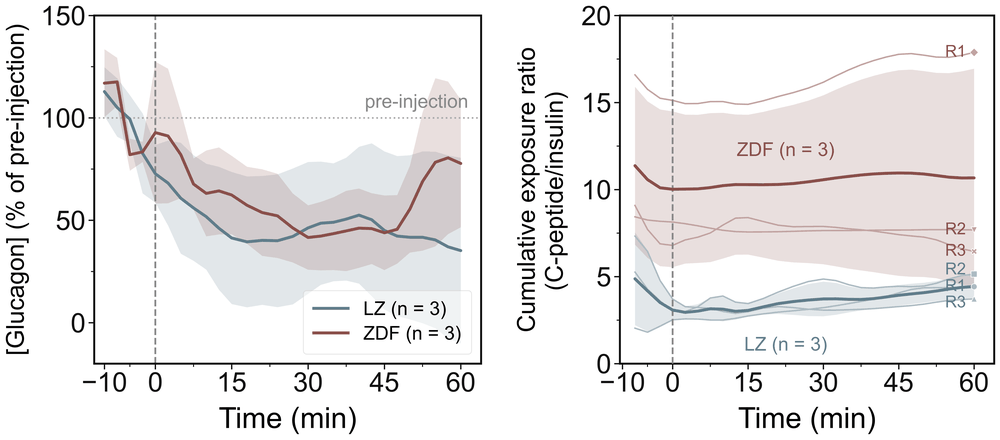

In [28]:
show("si_glucagon_percent_of_baseline", "si_cpeptide_insulin_exposure_ratio")

Continuous device record against the five ELISA blood draws: insulin and C-peptide of LZ R3.

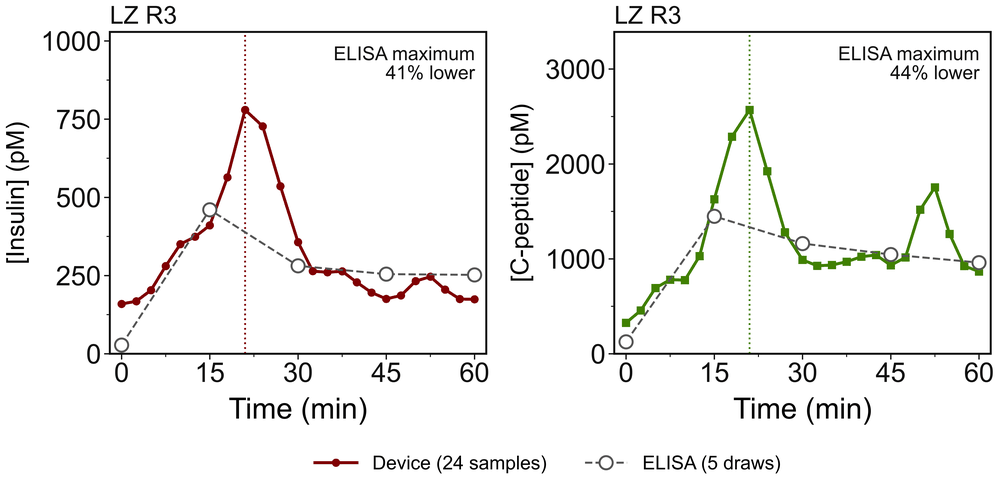

In [29]:
show("si_sampling_lz_r3")

How far the largest ELISA value lies below the device maximum, and how far apart their times are, in every rat.

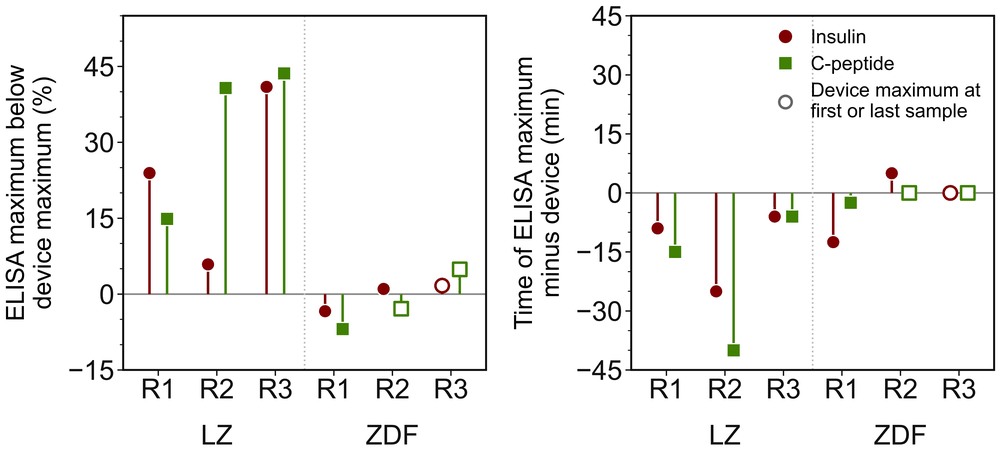

In [30]:
show("si_sampling_maxima")